# DeepDive / BOOTCAMP 02
### EDA · PCA · t-SNE · UMAP

**WORKBOOK — uzupełnij kod w komórkach TODO**

## 00 / START

Pracujemy na 178 próbkach wina i 13 cechach chemicznych. `wine_class` to etykieta tylko do kolorowania wykresów — nie bierze udziału w redukcji wymiarów.

**Cel:** porównać PCA, t-SNE i UMAP na tych samych danych. Czas: 60–75 min.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 20)
df = pd.read_csv("wine.csv")
df.head()

,sample_id,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,wine_class
0,W001,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,W002,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,W003,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,W004,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,W005,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


## 01 / EDA

Sprawdź wymiary, typy, brakujące wartości i duplikaty. Następnie policz statystyki opisowe. Nie usuwaj żadnych kolumn bez uzasadnienia.

In [2]:
# TODO: shape, info(), isna().sum(), duplicated().sum(), describe()
print("Wymiary:", df.shape)
df.info()
print("Braki:", df.isna().sum())
print("Duplikaty:", df.duplicated().sum())
display(df.describe().T.round(2))

Wymiary: (178, 15)
<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 15 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   sample_id                     178 non-null    str    
 1   alcohol                       178 non-null    float64
 2   malic_acid                    178 non-null    float64
 3   ash                           178 non-null    float64
 4   alcalinity_of_ash             178 non-null    float64
 5   magnesium                     178 non-null    float64
 6   total_phenols                 178 non-null    float64
 7   flavanoids                    178 non-null    float64
 8   nonflavanoid_phenols          178 non-null    float64
 9   proanthocyanins               178 non-null    float64
 10  color_intensity               178 non-null    float64
 11  hue                           178 non-null    float64
 12  od280/od315_of_diluted_wines  178 non-null    float64
 1

,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.00,0.81,11.03,12.36,13.05,13.68,14.83
malic_acid,178.0,2.34,1.12,0.74,1.60,1.87,3.08,5.80
ash,178.0,2.37,0.27,1.36,2.21,2.36,2.56,3.23
alcalinity_of_ash,178.0,19.49,3.34,10.60,17.20,19.50,21.50,30.00
magnesium,178.0,99.74,14.28,70.00,88.00,98.00,107.00,162.00
total_phenols,178.0,2.30,0.63,0.98,1.74,2.36,2.80,3.88
flavanoids,178.0,2.03,1.00,0.34,1.20,2.13,2.88,5.08
nonflavanoid_phenols,178.0,0.36,0.12,0.13,0.27,0.34,0.44,0.66
proanthocyanins,178.0,1.59,0.57,0.41,1.25,1.56,1.95,3.58
color_intensity,178.0,5.06,2.32,1.28,3.22,4.69,6.20,13.00


## 02 / ROZKŁADY I ZALEŻNOŚCI

Zobacz rozkład klas, histogram jednej cechy, boxplot innej oraz korelacje. Wskaż parę silnie skorelowanych cech.

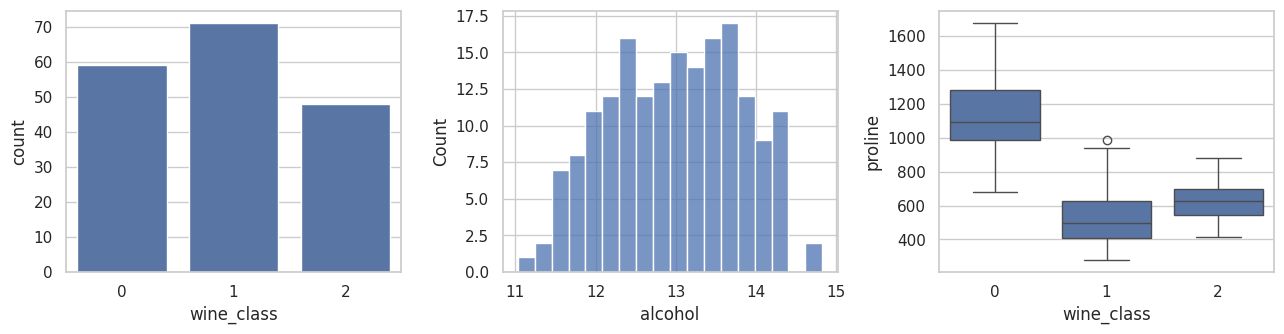

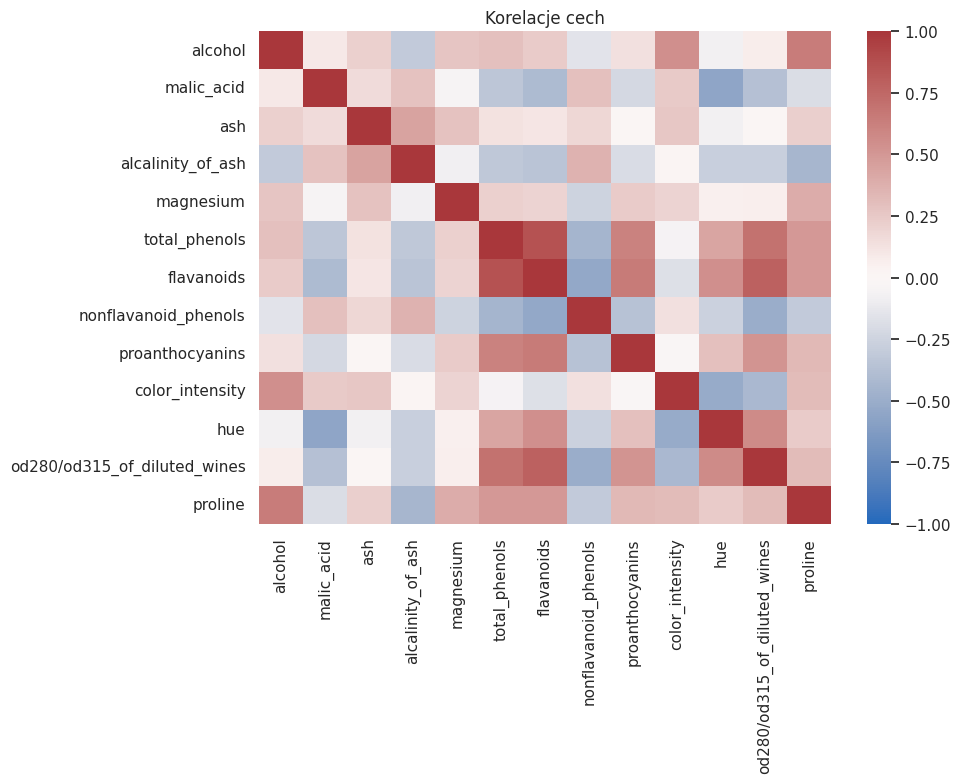

In [3]:
# TODO: countplot(wine_class), hist(alcohol), boxplot(x=wine_class, y=proline)
# TODO: heatmap korelacji cech numerycznych (bez wine_class)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
sns.countplot(data=df, x="wine_class", ax=ax[0])
sns.histplot(data=df, x="alcohol", bins=18, ax=ax[1])
sns.boxplot(data=df, x="wine_class", y="proline", ax=ax[2])
plt.tight_layout()
plt.show()

feature_cols = df.columns.drop(["sample_id", "wine_class"])
plt.figure(figsize=(10, 8))
sns.heatmap(df[feature_cols].corr(), cmap="vlag", center=0, vmin=-1, vmax=1)
plt.title("Korelacje cech")
plt.tight_layout()
plt.show()

## 03 / STANDARYZACJA

Oddziel cechy od etykiety. Wykonaj standaryzację (`StandardScaler`). Sprawdź średnie i odchylenia standardowe po transformacji.

In [4]:
# TODO: utwórz X, y; dopasuj StandardScaler; otrzymaj X_scaled
feature_cols = df.columns.drop(["sample_id", "wine_class"])
X = df[feature_cols]
y = df["wine_class"]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Średnie:", np.round(X_scaled.mean(axis=0), 2))
print("Odchylenia:", np.round(X_scaled.std(axis=0), 2))

Średnie: [-0. -0. -0. -0. -0.  0. -0.  0. -0.  0.  0.  0. -0.]
Odchylenia: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## 04 / PCA · PEŁNY MODEL

Dopasuj PCA bez ograniczania liczby składowych. Zapisz wartości własne, udział wyjaśnionej wariancji i wariancję skumulowaną.

In [5]:
# TODO: PCA(), fit(X_scaled); eigenvalues, explained_ratio, cumulative
pca_full = PCA().fit(X_scaled)
eigenvalues = pca_full.explained_variance_
explained_ratio = pca_full.explained_variance_ratio_
cumulative = np.cumsum(explained_ratio)
display(pd.DataFrame({
    "PC": np.arange(1, len(eigenvalues) + 1),
    "wartosc_wlasna": eigenvalues,
    "wariancja_%": 100 * explained_ratio,
    "skumulowana_%": 100 * cumulative
}).round(2))

,PC,wartosc_wlasna,wariancja_%,skumulowana_%
0,1,4.73,36.20,36.20
1,2,2.51,19.21,55.41
2,3,1.45,11.12,66.53
3,4,0.92,7.07,73.60
4,5,0.86,6.56,80.16
5,6,0.65,4.94,85.10
6,7,0.55,4.24,89.34
7,8,0.35,2.68,92.02
8,9,0.29,2.22,94.24
9,10,0.25,1.93,96.17


## 05 / PCA · TRZY KRYTERIA

**A. Kaiser:** zachowaj składowe z wartością własną > 1. **B. Osypisko:** obejrzyj spadek wartości własnych i wskaż „łokieć” (ocena wizualna). **C. Wyjaśniona zmienność:** znajdź minimalną liczbę składowych dla progu 70%, a dodatkowo 95%.

Uwaga: kryterium Kaisera stosujemy do PCA ze standaryzowanych zmiennych; wykres osypiska nie daje automatycznie jednoznacznej liczby.

Kaiser: 3; wariancja ≥70%: 4; wariancja ≥95%: 10


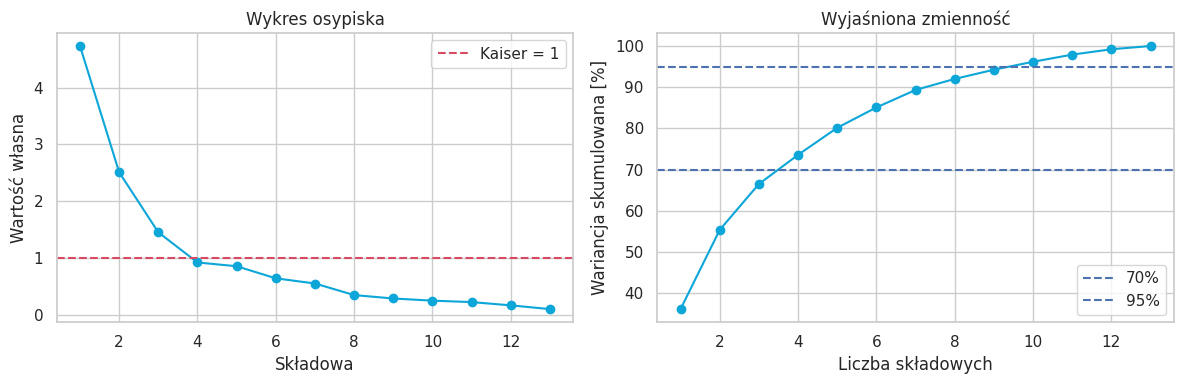

Osypisko: wskaż liczbę składowych na podstawie widocznego załamania wykresu.


In [6]:
# TODO: n_kaiser, n_70, n_95
# TODO: wykres osypiska oraz wykres skumulowanej wariancji
n_kaiser = int(np.sum(eigenvalues > 1))
n_70 = int(np.searchsorted(cumulative, .70) + 1)
n_95 = int(np.searchsorted(cumulative, .95) + 1)
print(f"Kaiser: {n_kaiser}; wariancja ≥70%: {n_70}; wariancja ≥95%: {n_95}")

pcs = np.arange(1, len(eigenvalues) + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(pcs, eigenvalues, "o-", color="#0CA6D8")
ax[0].axhline(1, color="#D84A64", linestyle="--", label="Kaiser = 1")
ax[0].set(xlabel="Składowa", ylabel="Wartość własna", title="Wykres osypiska")
ax[0].legend()
ax[1].plot(pcs, cumulative * 100, "o-", color="#0CA6D8")
for threshold in [70, 95]:
    ax[1].axhline(threshold, linestyle="--", label=f"{threshold}%")
ax[1].set(xlabel="Liczba składowych", ylabel="Wariancja skumulowana [%]", title="Wyjaśniona zmienność")
ax[1].legend()
plt.tight_layout()
plt.show()
print("Osypisko: wskaż liczbę składowych na podstawie widocznego załamania wykresu.")

## 06 / PCA · PROJEKCJA I ŁADUNKI

Zredukuj dane do 2D. Wykreśl punkty według klas. Następnie oblicz ładunki (`components_.T * sqrt(explained_variance_)`) i wykonaj prosty biplot: punkty + strzałki trzech cech o największych długościach wektorów ładunków.

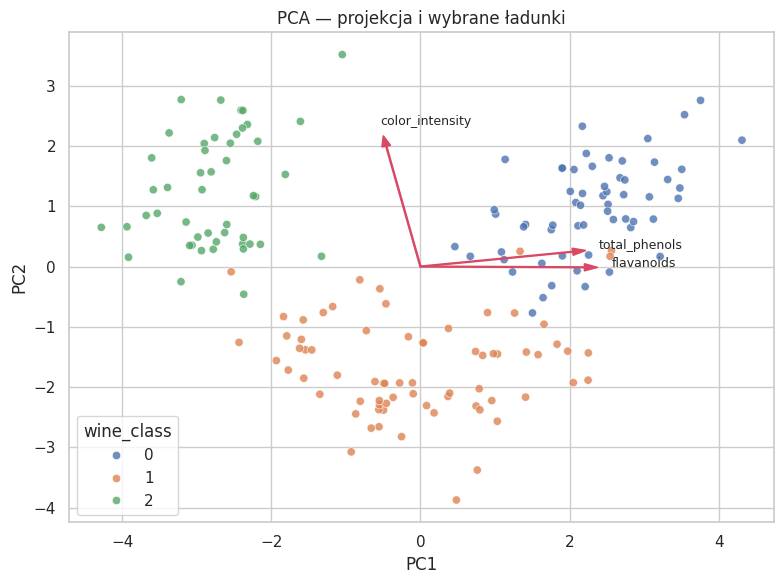

,PC1,PC2
alcohol,0.314,0.766
malic_acid,-0.533,0.356
ash,-0.004,0.501
alcalinity_of_ash,-0.521,-0.017
magnesium,0.309,0.475
total_phenols,0.859,0.103
flavanoids,0.920,-0.005
nonflavanoid_phenols,-0.649,0.046
proanthocyanins,0.682,0.062
color_intensity,-0.193,0.840


In [7]:
# TODO: PCA(n_components=2), fit_transform; scatter; loadings; biplot
pca2 = PCA(n_components=2)
Z_pca = pca2.fit_transform(X_scaled)
loadings = pca2.components_.T * np.sqrt(pca2.explained_variance_)

fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(x=Z_pca[:, 0], y=Z_pca[:, 1], hue=y.astype(str), ax=ax, alpha=.8)
ax.set(xlabel="PC1", ylabel="PC2", title="PCA — projekcja i wybrane ładunki")

top_idx = np.argsort(np.linalg.norm(loadings, axis=1))[-3:]
scale = min(np.ptp(Z_pca[:, 0]), np.ptp(Z_pca[:, 1])) * .35
for i in top_idx:
    dx, dy = loadings[i] * scale
    ax.arrow(0, 0, dx, dy, color="#D84A64", width=.015, head_width=.12, length_includes_head=True)
    ax.text(dx * 1.08, dy * 1.08, feature_cols[i], fontsize=9)
plt.tight_layout()
plt.show()

display(pd.DataFrame(loadings, index=feature_cols, columns=["PC1", "PC2"]).round(3))

## 07 / t-SNE · PERPLEXITY

Uruchom t-SNE dwa razy: `perplexity=5` i `perplexity=30`. Ustaw `random_state=42`. Porównaj lokalne grupowanie z PCA. Nie interpretuj odległości między odległymi skupiskami jako wiarygodnych odległości w danych źródłowych.

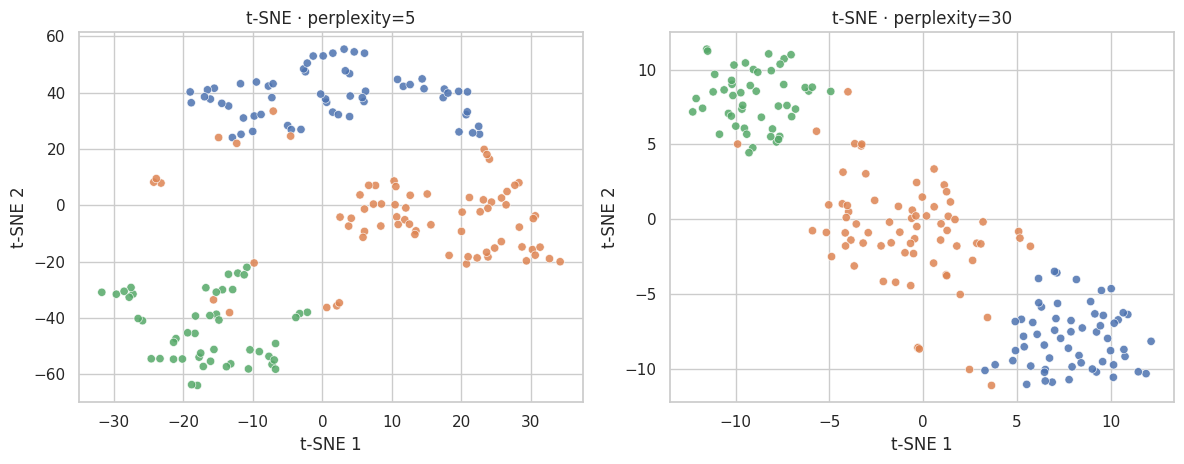

In [8]:
# TODO: TSNE(n_components=2, perplexity=5/30, random_state=42, init="pca", learning_rate="auto")
# TODO: dwa wykresy scatter obok siebie
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, perp in zip(axes, [5, 30]):
    Z = TSNE(n_components=2, perplexity=perp, random_state=42,
             init="pca", learning_rate="auto").fit_transform(X_scaled)
    sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=y.astype(str), ax=ax, legend=False, alpha=.85)
    ax.set(title=f"t-SNE · perplexity={perp}", xlabel="t-SNE 1", ylabel="t-SNE 2")
plt.tight_layout()
plt.show()

## 08 / UMAP · SĄSIEDZI

Uruchom UMAP dla `n_neighbors=5` i `n_neighbors=30`, z `min_dist=0.1` i `random_state=42`. Porównaj rozkład punktów. Jeśli brakuje pakietu, zainstaluj `umap-learn` w środowisku notebooka.

/home/jakub/.global_venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/jakub/.global_venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/jakub/.global_venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


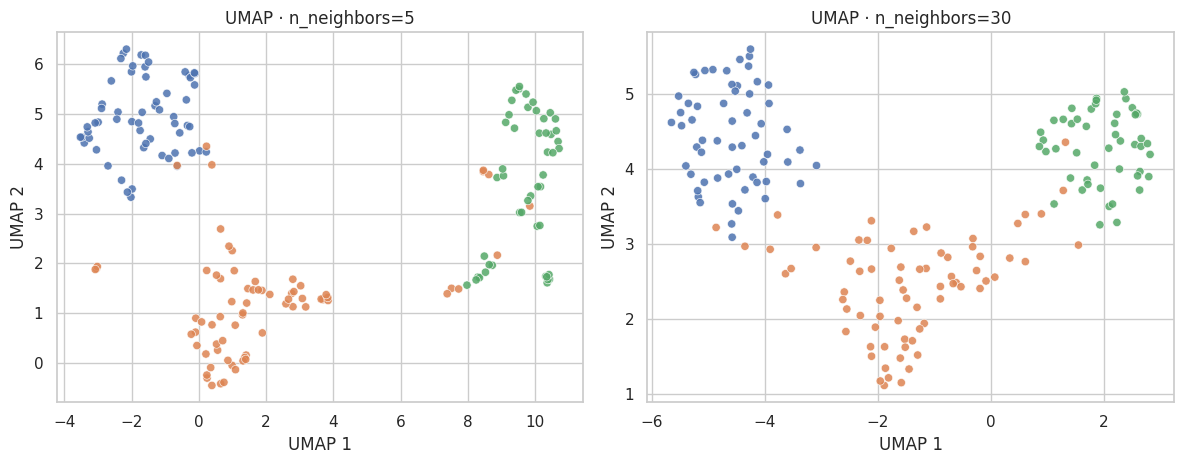

In [9]:
# TODO: import umap; UMAP(n_components=2, n_neighbors=5/30, min_dist=.1, random_state=42)
# TODO: dwa wykresy scatter

import umap

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, k in zip(axes, [5, 30]):
    Z = umap.UMAP(n_components=2, n_neighbors=k, min_dist=.1,
                  random_state=42).fit_transform(X_scaled)
    sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=y.astype(str), ax=ax, legend=False, alpha=.85)
    ax.set(title=f"UMAP · n_neighbors={k}", xlabel="UMAP 1", ylabel="UMAP 2")
plt.tight_layout()
plt.show()

## 09 / WNIOSKI

Odpowiedz krótko — 1–2 zdania na punkt.

1. Czy trzy kryteria PCA dają tę samą liczbę składowych? Które wybierasz i dlaczego?
2. Które cechy najmocniej wpływają na PC1 i PC2?
3. Co zmienia `perplexity` w t-SNE oraz `n_neighbors` w UMAP?
4. Którą metodę zastosujesz do kompresji cech przed modelem, a którą przede wszystkim do wizualizacji?

In [ ]:
# Odpowiedzi wpisz w komórce Markdown poniżej.

---
DeepDive · Data Science Bootcamp · 28.10.2026